# Section 2 · Task 2.1 — Visualize Quantum Circuits

**Exam:** C1000-179 *Fundamentals of Quantum Computing Using Qiskit v2.X Developer*
**Section 2:** Visualize quantum circuits, measurements, and states (≈ 11 % of the exam) → **Task 2.1: Visualize quantum circuits**
**Official reference from the study guide:** [Visualize circuits](https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits)
Also useful: [`QuantumCircuit.draw`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit#draw) · [`qiskit.visualization` API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/visualization)

---

### IBM's self-test applied here
1. **How** do you draw a circuit — which renderers exist, what do they return, how do you save, fold, style and scale a diagram?
2. **Why** do the options exist — when is `reverse_bits` the thing that makes a diagram match a textbook, and when is `plot_barriers=False` hiding something important?
3. **What goes wrong if you misread or mis-draw** a circuit? (qubit 0 is at the *top* but is the *rightmost* bit; a folded diagram is still one circuit; hidden barriers still constrain the compiler …)

### What you will be able to do afterwards
- Use `print(qc)`, `qc.draw()`, `qc.draw("mpl")`, `qc.draw("latex")` / `"latex_source"` and the standalone `circuit_drawer()`
- Say exactly **what type each renderer returns**
- Apply every option the study-guide page names: `output`, `filename`, `interactive`, `reverse_bits`, `plot_barriers`, `fold`, `style`, `scale`
- Read a diagram into code (and code into a diagram), including register labels and measurement wiring
- Know the extra options the API offers (`idle_wires`, `cregbundle`, `justify`, `initial_state`, `wire_order`, `with_layout`, `measure_arrows`, …)

Exercise cells are stubs returning `None`: the notebook runs end-to-end without your answers and every checker tells you if you haven't attempted it yet. **Solutions are at the end.**

In [1]:
import os, tempfile, warnings
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit import Parameter
from qiskit.visualization import circuit_drawer
from qiskit.providers.fake_provider import GenericBackendV2

print("qiskit", qiskit.__version__)

def _todo(name):
    print(f"⏳ {name}: not attempted yet — fill in the TODO above and re-run this cell.")

def ops(qc):
    return [(i.operation.name, tuple(qc.find_bit(q).index for q in i.qubits)) for i in qc.data]

qiskit 2.6.1


---
## 1 · Three ways to see a circuit: `print`, `draw()`, and the three renderers

The guide's first point: **printing a circuit and calling `draw()` give the same ASCII picture**, but they are *not* the same operation.

| | `print(qc)` | `qc.draw()` |
|---|---|---|
| Displays the diagram | ✅ (side effect) | ✅ in Jupyter (notebooks display a cell's last value) |
| Return value | `None` | **the diagram object** (no side effects) |

That return value is what you need if you want to save, post-process or embed a diagram.

We will reuse the exact circuit from the guide:

In [2]:
circuit = QuantumCircuit(3, 3)
circuit.x(1)
circuit.h(range(3))
circuit.cx(0, 1)
circuit.measure(range(3), range(3))

print(circuit)                 # prints the ASCII diagram; the *expression* print(...) evaluates to None

     ┌───┐          ┌─┐   
q_0: ┤ H ├───────■──┤M├───
     ├───┤┌───┐┌─┴─┐└╥┘┌─┐
q_1: ┤ X ├┤ H ├┤ X ├─╫─┤M├
     ├───┤└┬─┬┘└───┘ ║ └╥┘
q_2: ┤ H ├─┤M├───────╫──╫─
     └───┘ └╥┘       ║  ║ 
c: 3/═══════╩════════╩══╩═
            2        0  1 


In [3]:
d = circuit.draw()             # returns the diagram object; nothing is printed unless the cell ends with it
print(type(d).__name__)
d                               # last expression in the cell -> Jupyter displays it

TextDrawing


┌───┐          ┌─┐   
q_0: ┤ H ├───────■──┤M├───
     ├───┤┌───┐┌─┴─┐└╥┘┌─┐
q_1: ┤ X ├┤ H ├┤ X ├─╫─┤M├
     ├───┤└┬─┬┘└───┘ ║ └╥┘
q_2: ┤ H ├─┤M├───────╫──╫─
     └───┘ └╥┘       ║  ║ 
c: 3/═══════╩════════╩══╩═
            2        0  1

### 1.1 The three renderers (`output=`)

| `output=` | Library | Returns | Notes |
|---|---|---|---|
| `"text"` (default) | none (pure Python) | a text-drawing object (`str()` gives the ASCII art) | works everywhere, ideal while developing |
| `"mpl"` | **Matplotlib** | `matplotlib.figure.Figure` | most flexible: styles, scale, folding by layers |
| `"latex"` | LaTeX + the **`qcircuit`** package | `PIL.Image` | needs a LaTeX install; publication quality |
| `"latex_source"` | none | the **LaTeX source string** | no LaTeX install needed — compile it yourself |

> `"text"` and `"mpl"` need nothing special; `"latex"` is the one that depends on external software. The guide notes macOS users can get the packages through MacTeX.
>
> *Naming note:* the guide calls the text return value a "`TextDrawer` object"; in the installed Qiskit its class is called `TextDrawing`. The class name is an implementation detail — what matters is that `str(...)` of it is the ASCII art and that it is **not** a Matplotlib figure or an image.

mpl returns: matplotlib.figure.Figure


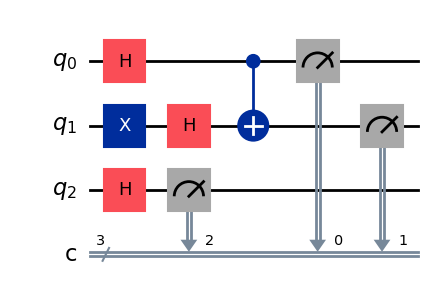

In [4]:
fig = circuit.draw(output="mpl")
print("mpl returns:", type(fig).__module__ + "." + type(fig).__name__)
fig

In [5]:
src = circuit.draw(output="latex_source")       # does not need a LaTeX installation
print("latex_source returns:", type(src).__name__, "| first lines of the LaTeX document:")
print("\n".join(src.splitlines()[:6]))

latex_source returns: str | first lines of the LaTeX document:
\documentclass[border=2px]{standalone}

\usepackage[braket, qm]{qcircuit}
\usepackage{graphicx}

\begin{document}


In [6]:
# output="latex" renders via a real LaTeX toolchain and returns a PIL image. Guarded so the notebook runs
# on machines without LaTeX installed:
try:
    img = circuit.draw(output="latex")
    print("latex returns:", type(img).__module__ + "." + type(img).__name__)
except Exception as e:
    print("LaTeX rendering unavailable here:", type(e).__name__, "— that is why 'latex_source' exists.")

latex returns: PIL.Image.Image


---
## 2 · Reading a diagram correctly

```
     ┌───┐          ┌─┐
q_0: ┤ H ├───────■──┤M├───
     ├───┤┌───┐┌─┴─┐└╥┘┌─┐
q_1: ┤ X ├┤ H ├┤ X ├─╫─┤M├
     ├───┤└┬─┬┘└───┘ ║ └╥┘
q_2: ┤ H ├─┤M├───────╫──╫─
     └───┘ └╥┘       ║  ║
c: 3/═══════╩════════╩══╩═
            2        0  1
```

How to read it:

- **Time flows left → right.** Gates in the same vertical slice act in parallel (if on different qubits).
- **One horizontal line per qubit**, labelled `q_0, q_1, …` — **qubit 0 is drawn at the top**. (But remember the *bit-string* convention: qubit 0 is the **rightmost** character of a result like `'101'`. The diagram order and the bit-string order are *opposite* — a classic source of confusion.)
- A **double line** is a classical register. `c: 3/` means "register `c`, 3 bits, bundled into one line". The small numbers **under** each measurement are *which classical bit* receives the result.
- `■` is a control, `┤ X ├` on the other qubit is the target of a CNOT. A vertical `║`/`╥` connects a measurement to its classical bit.
- Wires, box labels and registers come from the circuit's **register names** (`q`, `c`, or your own).

Let's demonstrate how the numbers under the measurements change when the wiring changes:

In [7]:
qc = QuantumCircuit(3, 3)
qc.h(0)
qc.measure(0, 2)          # qubit 0 -> classical bit 2
qc.measure(1, 1)          # qubit 1 -> classical bit 1
qc.measure(2, 0)          # qubit 2 -> classical bit 0
print(qc)
print("\nclassical bit 0 is the RIGHTMOST character of a counts key, so qubit 0's result will appear at the LEFT:")
print("  key = c2 c1 c0 = (result of qubit 0)(qubit 1)(qubit 2)")

     ┌───┐   ┌─┐
q_0: ┤ H ├───┤M├
     └┬─┬┘   └╥┘
q_1: ─┤M├─────╫─
      └╥┘ ┌─┐ ║ 
q_2: ──╫──┤M├─╫─
       ║  └╥┘ ║ 
c: 3/══╩═══╩══╩═
       1   0  2 

classical bit 0 is the RIGHTMOST character of a counts key, so qubit 0's result will appear at the LEFT:
  key = c2 c1 c0 = (result of qubit 0)(qubit 1)(qubit 2)


---
## 3 · Saving and displaying: `filename` and `interactive`

Large circuits are unreadable inline. The guide's advice: **save to a file** and zoom in.

- `filename="circuit.jpeg"` (mpl) saves an image; `filename="circuit.pdf"` (latex) saves a PDF.
- `interactive=True` opens the image in a **new window** (for `mpl` / `latex`) — not reliable inside notebooks.
- Outside Jupyter, an object returned by `draw()` is **not displayed automatically** — use `filename` or show/save the figure yourself.

In [8]:
tmpdir = tempfile.mkdtemp()
path_png = os.path.join(tmpdir, "circuit-mpl.png")
path_jpg = os.path.join(tmpdir, "circuit-mpl.jpeg")

circuit.draw(output="mpl", filename=path_png)          # same call, now ALSO writes a file
circuit.draw(output="mpl", filename=path_jpg)
for p in (path_png, path_jpg):
    print(f"{os.path.basename(p):<18} exists={os.path.exists(p)}  bytes={os.path.getsize(p)}")

circuit-mpl.png    exists=True  bytes=17765
circuit-mpl.jpeg   exists=True  bytes=21937


In [9]:
# Because mpl returns a normal Matplotlib Figure you can ALSO use Matplotlib's own saving:
fig = circuit.draw(output="mpl")
fig.savefig(os.path.join(tmpdir, "via_matplotlib.svg"))     # vector format, great for papers
print(sorted(os.listdir(tmpdir)))
plt.close("all")

['circuit-mpl.jpeg', 'circuit-mpl.png', 'via_matplotlib.svg']


---
## 4 · Options shared by all renderers: `reverse_bits` and `plot_barriers`

The guide demonstrates these on a multi-register circuit. We use the same one.

- **`reverse_bits=True`** draws the *highest-index* qubit at the top. Use it to make a diagram match a textbook that puts qubit $n-1$ at the top, so the **diagram order matches the bit-string order**. It changes the *picture only* — not the circuit.
- **`plot_barriers=False`** hides barriers in the picture. The barriers are **still in the circuit** and still constrain the transpiler — you are only hiding them.

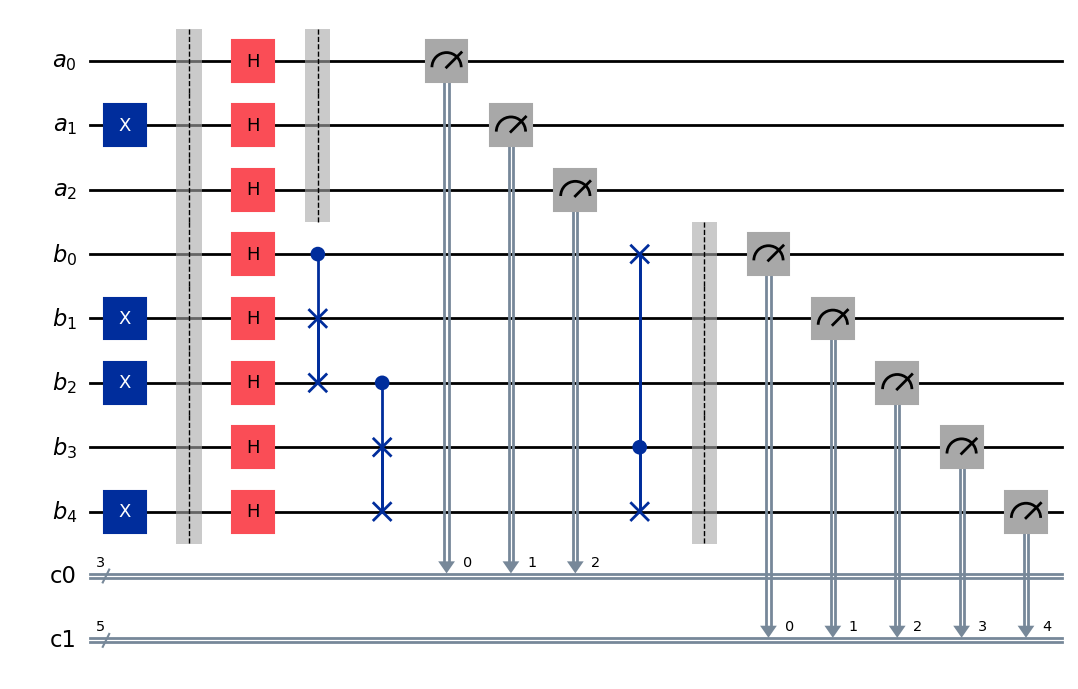

In [10]:
q_a = QuantumRegister(3, name="a")
q_b = QuantumRegister(5, name="b")
c_a = ClassicalRegister(3)
c_b = ClassicalRegister(5)

big = QuantumCircuit(q_a, q_b, c_a, c_b)
big.x(q_a[1]); big.x(q_b[1]); big.x(q_b[2]); big.x(q_b[4])
big.barrier()
big.h(q_a)
big.barrier(q_a)
big.h(q_b)
big.cswap(q_b[0], q_b[1], q_b[2])
big.cswap(q_b[2], q_b[3], q_b[4])
big.cswap(q_b[3], q_b[4], q_b[0])
big.barrier(q_b)
big.measure(q_a, c_a)
big.measure(q_b, c_b)

big.draw(output="mpl")

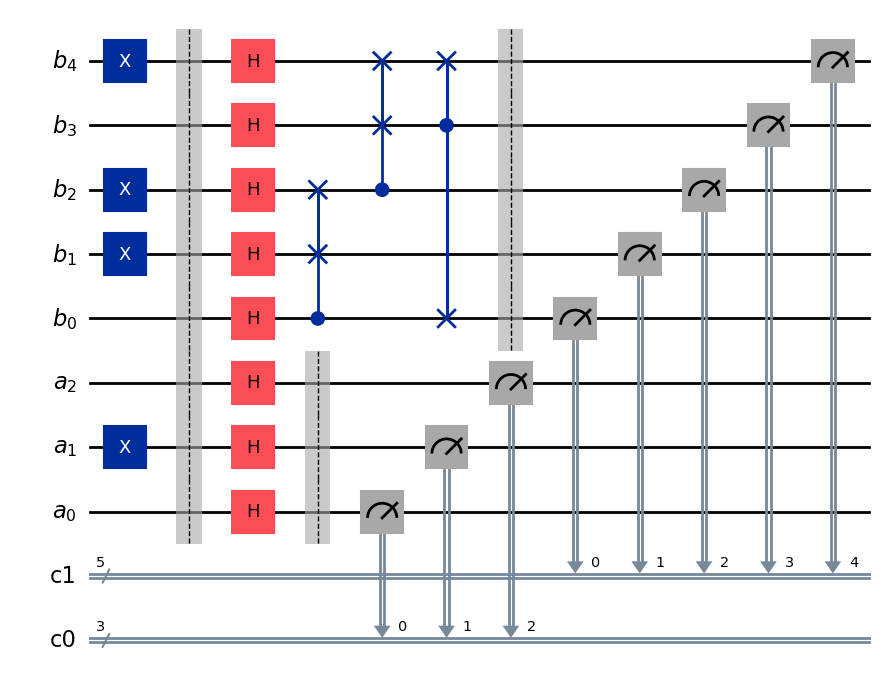

In [11]:
big.draw(output="mpl", reverse_bits=True)

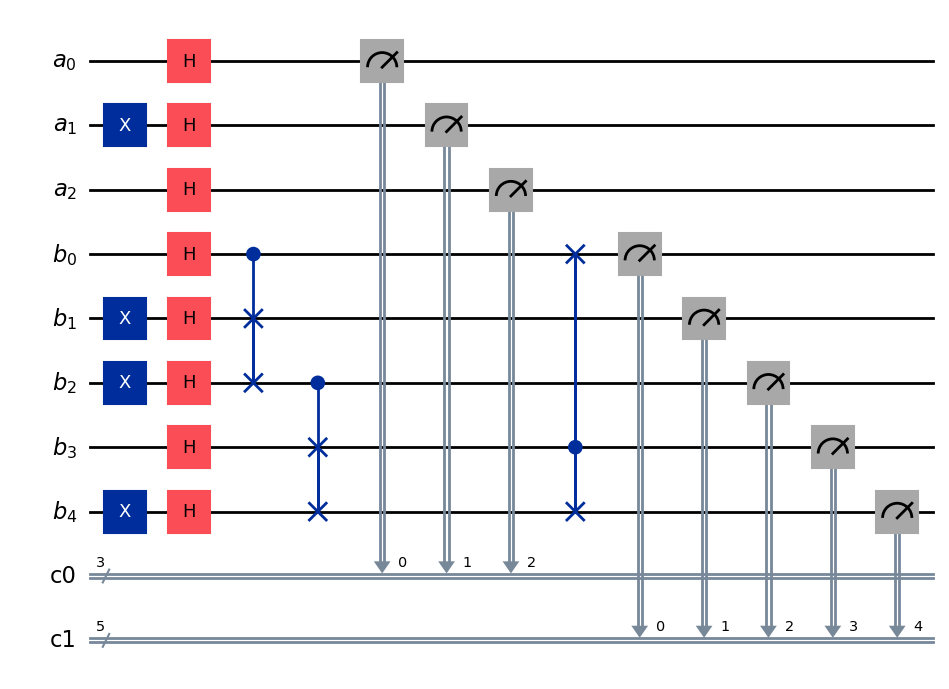

In [12]:
big.draw(output="mpl", plot_barriers=False)

In [13]:
# Prove that these two options only change the PICTURE, not the circuit
shown_without_barriers = big.draw(output="text", plot_barriers=False)
print("barriers still present in the circuit:", big.count_ops().get("barrier"), "barrier instructions")
print("size() ignores barriers:", big.size(), "| depth() :", big.depth())

# reverse_bits flips the vertical order of the wires. Compare first line of each text drawing:
first = lambda s: str(s).splitlines()[1].split(":")[0].strip()
print("first wire, default       :", first(big.draw("text")))
print("first wire, reverse_bits  :", first(big.draw("text", reverse_bits=True)))

barriers still present in the circuit: 3 barrier instructions
size() ignores barriers: 23 | depth() : 6
first wire, default       : a_0
first wire, reverse_bits  : b_4


---
## 5 · Renderer-specific options: `fold`, `style`, `scale`

| Option | Applies to | Effect |
|---|---|---|
| `fold=N` | text, mpl | **Wrap** the diagram. In `text`, `N` is the max **characters per line**; in `mpl`, `N` is the max number of **visual layers** per row. `fold=-1` disables folding. |
| `style=…` | mpl | Colours/outlines: a **named style** (`"iqp"`, `"iqp-dark"`, `"clifford"`, `"bw"`, `"textbook"`) or a **dict** such as `{"backgroundcolor": "lightgreen"}` |
| `scale=x` | mpl, latex | Multiply the rendered size (`0.5` = half size) |

### 5.1 `fold`

In [14]:
wide = QuantumCircuit(1)
for _ in range(10):
    wide.h(0)

print(wide.draw(output="text", fold=40))     # lines no longer than 40 characters; » « mark continuation

   ┌───┐┌───┐┌───┐┌───┐┌───┐┌───┐┌───┐»
q: ┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├»
   └───┘└───┘└───┘└───┘└───┘└───┘└───┘»
«   ┌───┐┌───┐┌───┐
«q: ┤ H ├┤ H ├┤ H ├
«   └───┘└───┘└───┘


In [15]:
print("Without folding the whole circuit is one long line:")
print(wide.draw(output="text", fold=-1))

Without folding the whole circuit is one long line:
   ┌───┐┌───┐┌───┐┌───┐┌───┐┌───┐┌───┐┌───┐┌───┐┌───┐
q: ┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├┤ H ├
   └───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘


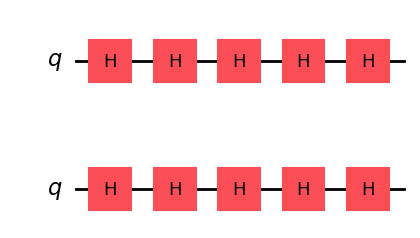

In [16]:
wide.draw(output="mpl", fold=5)             # 5 layers per row in mpl

> **Reading folded text diagrams:** the `»` at the end of a line and `«` at the start of the next one mean *"the circuit continues on the next block"*. It is still **one** circuit, read top block to bottom block.

### 5.2 `style`

style = 'iqp'


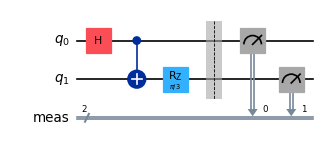

style = 'iqp-dark'


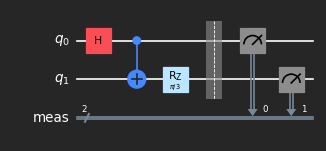

style = 'clifford'


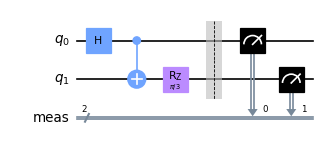

style = 'bw'


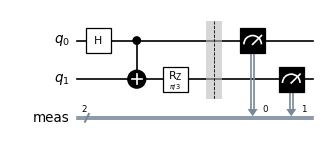

style = 'textbook'


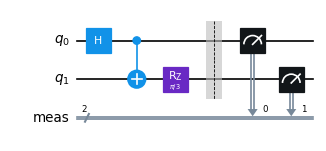

In [17]:
style_demo = QuantumCircuit(2)
style_demo.h(0); style_demo.cx(0, 1); style_demo.rz(np.pi / 3, 1); style_demo.measure_all()

for name in ["iqp", "iqp-dark", "clifford", "bw", "textbook"]:
    print("style =", repr(name))
    display(style_demo.draw(output="mpl", style=name, scale=0.6))
plt.close("all")

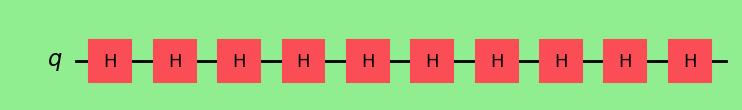

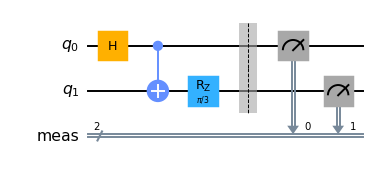

In [18]:
# A dict style changes individual properties. The guide's example:
display(wide.draw(output="mpl", style={"backgroundcolor": "lightgreen"}))

# You can also recolour specific gates with 'displaycolor': gate-name -> (box colour, text colour)
custom = {"displaycolor": {"h": ("#FFB000", "#000000"), "cx": ("#648FFF", "#FFFFFF")}}
display(style_demo.draw(output="mpl", style=custom, scale=0.7))
plt.close("all")

### 5.3 `scale`

scale=1.0: figure size = 6.64 x 2.84 inches


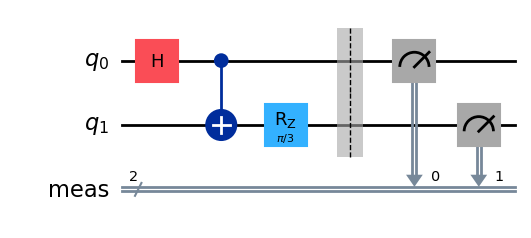

scale=0.5: figure size = 3.32 x 1.42 inches


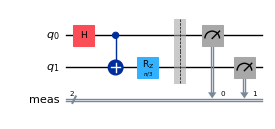

In [19]:
for s in (1.0, 0.5):
    fig = style_demo.draw(output="mpl", scale=s)
    w, h = fig.get_size_inches()
    print(f"scale={s}: figure size = {w:.2f} x {h:.2f} inches")
    display(fig)
plt.close("all")

---
## 6 · The standalone `circuit_drawer()` function

`circuit_drawer(circuit, …)` is part of the **stable public interface** in `qiskit.visualization`. It behaves **identically to `circuit.draw(…)`**, but takes the circuit as a *required first argument* — convenient when you prefer a self-contained function (e.g. inside a plotting helper).

identical text output: True


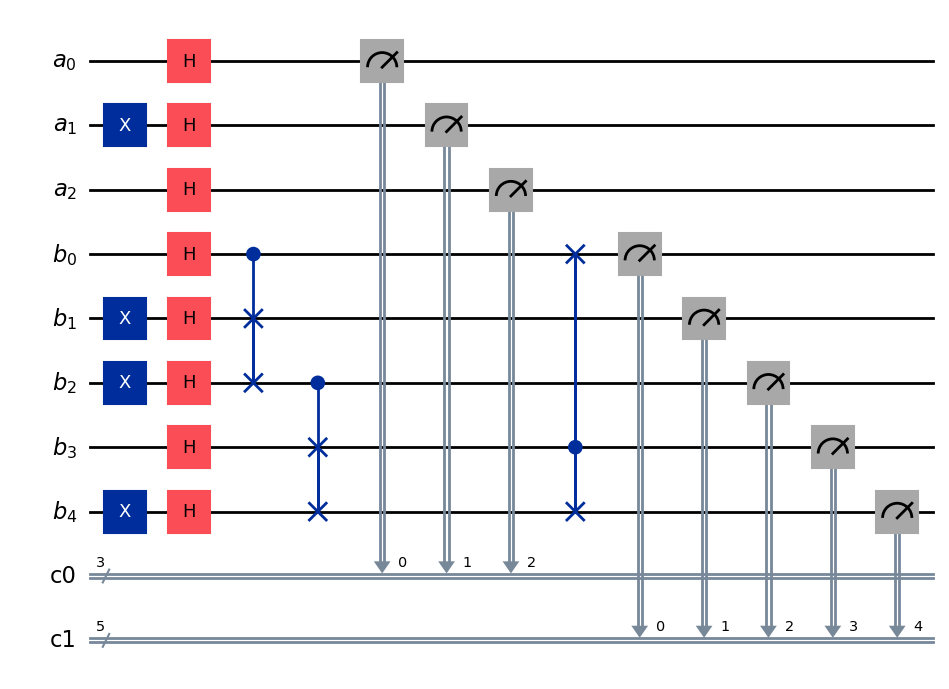

In [20]:
a = circuit_drawer(big, output="text", plot_barriers=False, fold=60)
b = big.draw(output="text", plot_barriers=False, fold=60)
print("identical text output:", str(a) == str(b))
circuit_drawer(big, output="mpl", plot_barriers=False)

---
## 7 · More options from the API (beyond the guide page)

The guide page lists the options above; the `draw()` API has several more. They are fair game for understanding diagrams, so here is each one with a one-line demonstration (all with the fast `text` renderer).

| Option | Effect |
|---|---|
| `idle_wires=False` | hide wires that nothing acts on |
| `justify="left" / "right" / "none"` | how gates are aligned in layers (default `"left"`) |
| `initial_state=True` | print the initial state `|0⟩` at the start of each qubit wire |
| `cregbundle=False` | draw each classical bit on its own line instead of one bundled register line |
| `wire_order=[…]` | custom ordering of wires (quantum wires first by index, then classical, as a list of indices) |
| `with_layout=False` | for a *transpiled* circuit: hide the `virtual -> physical` layout labels |
| `measure_arrows=True` | draw measurements as arrows to the classical wire (mpl) |
| `vertical_compression="low"/"medium"/"high"` | text renderer: how tightly to pack rows |
| `expr_len`, `barrier_label_len` | truncate long classical-expression / barrier labels |

In [21]:
demo = QuantumCircuit(4, 2)           # qubit 3 is never touched
demo.h(0); demo.barrier([0, 1, 2], label="sync"); demo.cx(0, 1); demo.t(2)      # barrier on q0-q2 only: q3 stays idle
demo.measure([0, 1], [0, 1])

print("default:");                          print(demo.draw("text"))
print("\nidle_wires=False  (qubit 3 hidden):"); print(demo.draw("text", idle_wires=False))
print("\ninitial_state=True:");              print(demo.draw("text", initial_state=True))
print("\ncregbundle=False:");                print(demo.draw("text", cregbundle=False))

default:
     ┌───┐ sync      ┌─┐   
q_0: ┤ H ├──░─────■──┤M├───
     └───┘  ░   ┌─┴─┐└╥┘┌─┐
q_1: ───────░───┤ X ├─╫─┤M├
            ░   ├───┤ ║ └╥┘
q_2: ───────░───┤ T ├─╫──╫─
            ░   └───┘ ║  ║ 
q_3: ─────────────────╫──╫─
                      ║  ║ 
c: 2/═════════════════╩══╩═
                      0  1 

idle_wires=False  (qubit 3 hidden):
     ┌───┐ sync      ┌─┐   
q_0: ┤ H ├──░─────■──┤M├───
     └───┘  ░   ┌─┴─┐└╥┘┌─┐
q_1: ───────░───┤ X ├─╫─┤M├
            ░   ├───┤ ║ └╥┘
q_2: ───────░───┤ T ├─╫──╫─
            ░   └───┘ ║  ║ 
c: 2/═════════════════╩══╩═
                      0  1 

initial_state=True:
        ┌───┐ sync      ┌─┐   
q_0: |0>┤ H ├──░─────■──┤M├───
        └───┘  ░   ┌─┴─┐└╥┘┌─┐
q_1: |0>───────░───┤ X ├─╫─┤M├
               ░   ├───┤ ║ └╥┘
q_2: |0>───────░───┤ T ├─╫──╫─
               ░   └───┘ ║  ║ 
q_3: |0>─────────────────╫──╫─
                         ║  ║ 
 c: 0 2/═════════════════╩══╩═
                         0  1 

cregbundle=False:
     ┌───┐ sy

In [22]:
j = QuantumCircuit(2)
j.h(0); j.h(0); j.h(0)          # three gates on q0 ...
j.x(1)                          # ... but only one gate on q1, which is free to sit anywhere
print("justify='left'  (default) — the lone X is pushed as early as possible:"); print(j.draw("text", justify="left"))
print("\njustify='right' — the lone X is pushed as late as possible:");          print(j.draw("text", justify="right"))
print("\nsame circuit, same unitary — only the picture differs.")

justify='left'  (default) — the lone X is pushed as early as possible:
     ┌───┐┌───┐┌───┐
q_0: ┤ H ├┤ H ├┤ H ├
     ├───┤└───┘└───┘
q_1: ┤ X ├──────────
     └───┘          

justify='right' — the lone X is pushed as late as possible:
     ┌───┐┌───┐┌───┐
q_0: ┤ H ├┤ H ├┤ H ├
     └───┘└───┘├───┤
q_1: ──────────┤ X ├
               └───┘

same circuit, same unitary — only the picture differs.


In [23]:
# Transpiled circuits remember their layout; with_layout controls whether the 'virtual -> physical' label shows
backend = GenericBackendV2(num_qubits=5, coupling_map=[[0, 1], [1, 2], [2, 3], [3, 4]], seed=7)
bell = QuantumCircuit(2, 2); bell.h(0); bell.cx(0, 1); bell.measure([0, 1], [0, 1])
tb = transpile(bell, backend, initial_layout=[2, 3], seed_transpiler=1)
print("with_layout=True (default):"); print(tb.draw("text", idle_wires=False))
print("\nwith_layout=False:");        print(tb.draw("text", with_layout=False, idle_wires=False))

with_layout=True (default):
global phase: π/4
         ┌─────────┐┌────┐┌─────────┐     ┌─┐   
q_0 -> 2 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├──■──┤M├───
         └─────────┘└────┘└─────────┘┌─┴─┐└╥┘┌─┐
q_1 -> 3 ────────────────────────────┤ X ├─╫─┤M├
                                     └───┘ ║ └╥┘
    c: 2/══════════════════════════════════╩══╩═
                                           0  1 

with_layout=False:
global phase: π/4
     ┌─────────┐┌────┐┌─────────┐     ┌─┐   
q_2: ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├──■──┤M├───
     └─────────┘└────┘└─────────┘┌─┴─┐└╥┘┌─┐
q_3: ────────────────────────────┤ X ├─╫─┤M├
                                 └───┘ ║ └╥┘
c: 2/══════════════════════════════════╩══╩═
                                       0  1 


---
## 8 · What else shows up in diagrams

### 8.1 Parameters, custom gates and controls

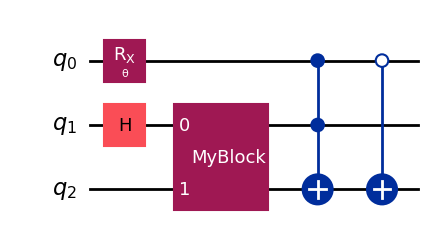

In [24]:
theta = Parameter("θ")                        # a symbolic parameter (Task 3.2 covers these in depth)
mix = QuantumCircuit(3, name="mix")
mix.rx(theta, 0)
mix.h(1)
mix.append(QuantumCircuit(2, name="MyBlock").to_gate(), [1, 2])      # boxed custom gate, label = circuit name
mix.ccx(0, 1, 2)
from qiskit.circuit.library import XGate
mix.append(XGate().control(1, ctrl_state=0), [0, 2])                 # open control -> hollow dot
mix.draw("mpl")

In [25]:
# Boxed gates stay boxed until you decompose them
inner = QuantumCircuit(2, name="Bell")
inner.h(0); inner.cx(0, 1)
outer = QuantumCircuit(2); outer.append(inner.to_gate(), [0, 1])
print("boxed:"); print(outer.draw("text"))
print("\ndecompose():"); print(outer.decompose().draw("text"))

boxed:
     ┌───────┐
q_0: ┤0      ├
     │  Bell │
q_1: ┤1      ├
     └───────┘

decompose():
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


### 8.2 Dynamic circuits (preview of Task 3.1)
Classical control flow is drawn with **boxes** (`If`, `Else`, `While`, `For`, `Switch`) and a condition box on the classical wire. In the mpl drawing, a **solid circle** on a classical bit means "condition on value 1"; an **outlined circle** means "condition on 0".

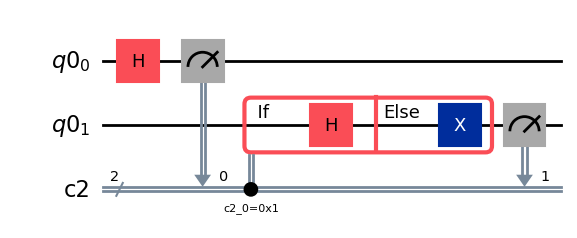

In [26]:
q = QuantumRegister(2); c = ClassicalRegister(2)
dyn = QuantumCircuit(q, c)
dyn.h(0)
dyn.measure(0, c[0])
with dyn.if_test((c[0], 1)) as else_:
    dyn.h(1)
with else_:
    dyn.x(1)
dyn.measure(1, c[1])
dyn.draw("mpl")

### 8.3 Drawings that are *not* of a circuit's gate list
The guide's *Next steps* point to circuit-**timing** visualisations; other drawers live in the same module and appear on the exam-adjacent documentation:

| Function | Draws |
|---|---|
| `timeline_drawer(scheduled_circuit)` | gate timing on each qubit (needs a *scheduled* circuit with a `Target`/durations) |
| `dag_drawer(dag)` | the circuit as a directed acyclic graph (needs Graphviz) |
| `pass_manager_drawer(pm)` | the stages/passes of a transpiler pipeline (needs Graphviz) |

They are not part of the study-guide reference for this task, so we only list them.

---
## 9 · Gotchas checklist

1. **`print(qc)` returns `None`;** `qc.draw()` **returns** the diagram. If you want to save or reuse it, use `draw`.
2. **Return types differ by renderer:** `text` → text-drawing object, `mpl` → `matplotlib.figure.Figure`, `latex` → `PIL.Image`, `latex_source` → `str`.
3. **Only `latex` needs LaTeX** (plus the `qcircuit` package). `text` and `mpl` do not.
4. **Qubit 0 is at the top of the diagram but is the rightmost bit of a result string.** `reverse_bits=True` reorders the drawing; it never changes the circuit.
5. **`plot_barriers=False` only hides barriers** from the picture. They remain in `count_ops()`, and they remain compile-time barriers.
6. **`fold` means different things:** characters per line in `text`, layers per row in `mpl`. `fold=-1` turns folding off.
7. **`style` and `scale` are mpl/latex features,** not text.
8. **Folded diagrams are still one circuit** — `»` / `«` mark continuation.
9. **Outside Jupyter, `draw()` shows nothing by itself.** Save with `filename=` (or `fig.savefig`) or show the figure explicitly. `interactive=True` pops up a window and is unreliable inside notebooks.
10. **Names matter:** the label inside a boxed custom gate is the circuit's `name`; `decompose()` expands boxes one level at a time.
11. **Very large circuits:** draw to a file instead of inline.
12. **A barrier on *all* qubits makes every wire "active":** `idle_wires=False` will not hide a qubit that a full-width `qc.barrier()` touches. Use `qc.barrier(qubits)` for the subset you mean.

---
## 10 · Exercises

### Exercise 1 — diagram → code
Below is the text drawing of an unknown 3-qubit circuit. **Rebuild it** (gates, order and qubits; the `Ry` angle is $\pi/3$).

In [27]:
MYSTERY = '                ┌───┐      \nq_0: ───────────┤ X ├─■────\n     ┌─────────┐└─┬─┘ │    \nq_1: ┤ Ry(π/3) ├──┼───■──X─\n     └──┬───┬──┘  │      │ \nq_2: ───┤ H ├─────■──────X─\n        └───┘              '
print(MYSTERY)

                ┌───┐      
q_0: ───────────┤ X ├─■────
     ┌─────────┐└─┬─┘ │    
q_1: ┤ Ry(π/3) ├──┼───■──X─
     └──┬───┬──┘  │      │ 
q_2: ───┤ H ├─────■──────X─
        └───┘              


In [28]:
def exercise_1():
    # TODO: return the QuantumCircuit that produces the diagram above
    return None

ans1 = exercise_1()

In [29]:
def check_1(qc):
    if qc is None: return _todo("Exercise 1")
    assert str(qc.draw("text")) == MYSTERY, "your circuit draws differently:\n" + str(qc.draw("text"))
    print("✅ Exercise 1 passed — your circuit draws exactly like the target.")
check_1(ans1)

⏳ Exercise 1: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 2 — pick the options
Return a **dict of keyword arguments** `kw` such that `qc.draw(**kw)` gives a *text* diagram in which: (a) the **highest** qubit is drawn at the **top**, (b) **barriers are hidden**, and (c) **idle wires are removed**.

In [30]:
def exercise_2():
    # TODO: return a dict of draw() keyword arguments
    return None

ans2 = exercise_2()

In [31]:
def check_2(kw):
    if kw is None: return _todo("Exercise 2")
    t = QuantumCircuit(4, 2)
    t.h(0); t.barrier([0, 1, 2]); t.cx(0, 1); t.barrier([0, 1, 2]); t.t(2); t.measure([0, 1], [0, 1])      # qubit 3 idle
    got = str(t.draw(**{"output": "text", **kw}))
    want = str(t.draw(output="text", reverse_bits=True, plot_barriers=False, idle_wires=False))
    assert got == want, "diagram differs from the target:\n" + got
    print("✅ Exercise 2 passed — three options, one picture.")
check_2(ans2)

⏳ Exercise 2: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 3 — save a diagram
Write `save_diagram(qc, path)` that **saves a PNG** of the circuit using the Matplotlib renderer, **`bw` style**, **scale 0.8**, and returns nothing. (Use `draw`'s own saving option.)

In [32]:
def save_diagram(qc, path):
    # TODO: save a PNG at `path` using output='mpl', style='bw', scale=0.8
    return None

In [33]:
def check_3():
    p = os.path.join(tempfile.mkdtemp(), "out.png")
    t = QuantumCircuit(2); t.h(0); t.cx(0, 1)
    save_diagram(t, p)
    if not os.path.exists(p): return _todo("Exercise 3")
    with open(p, "rb") as f:
        assert f.read(8) == b"\x89PNG\r\n\x1a\n", "file exists but is not a PNG"
    assert os.path.getsize(p) > 1000, "PNG looks empty"
    print("✅ Exercise 3 passed — PNG written,", os.path.getsize(p), "bytes.")
    plt.close("all")
check_3()

⏳ Exercise 3: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 4 — name the box
Return a 3-qubit circuit that contains a **boxed 2-qubit gate named `"MyBlock"`** (build it from any small sub-circuit) so that the text drawing **shows the name `MyBlock`**, while the **decomposed** version's drawing **does not**.

In [34]:
def exercise_4():
    # TODO: return a 3-qubit circuit containing a boxed gate called "MyBlock"
    return None

ans4 = exercise_4()

In [35]:
def check_4(qc):
    if qc is None: return _todo("Exercise 4")
    assert qc.num_qubits == 3, "need 3 qubits"
    assert "MyBlock" in str(qc.draw("text")), "the box name is not visible in the drawing"
    assert "MyBlock" not in str(qc.decompose().draw("text")), "decompose() should expand the box"
    print("✅ Exercise 4 passed — boxed gates show their name until decomposed.")
check_4(ans4)

⏳ Exercise 4: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 5 — which renderer?
For each need, return the correct `output=` string (`"text"`, `"mpl"`, `"latex"`, or `"latex_source"`) as a dict:

- `quick_look`: fastest look while developing, works over SSH with no GUI
- `publication_source`: the LaTeX **source code** for a paper, on a machine without LaTeX
- `styled_figure`: a Matplotlib `Figure` object you can recolour with `style=`

In [36]:
def exercise_5():
    # TODO: return {"quick_look": ..., "publication_source": ..., "styled_figure": ...}
    return None

ans5 = exercise_5()

In [37]:
def check_5(d):
    if d is None: return _todo("Exercise 5")
    assert d == {"quick_look": "text", "publication_source": "latex_source", "styled_figure": "mpl"}, f"got {d}"
    print("✅ Exercise 5 passed.")
check_5(ans5)

⏳ Exercise 5: not attempted yet — fill in the TODO above and re-run this cell.


### Playground
- Draw the same circuit with `justify="left"` and `"right"`. Which gate moves? Why does the unitary not change?
- Take the 8-qubit GHZ circuit; compare `fold=-1`, `fold=30`, and saving to a file.
- Transpile a circuit to `GenericBackendV2` with a line coupling map and draw it with and without `with_layout`.
- Build `qc.measure_all()` on 3 qubits and draw it with `cregbundle=False`. What is the register called?

---
## 11 · Exam-style questions

**Q1.** Which statement about `print(qc)` and `qc.draw()` is correct?
- A) They are identical  B) `print` returns the drawing object, `draw` returns `None`  C) `draw()` returns the diagram object; `print(qc)` returns `None`  D) `draw()` always saves a file

<details><summary>Answer</summary>

**C.**
</details>

**Q2.** What does `qc.draw(output="mpl")` return?
- A) a string  B) a `PIL.Image`  C) a `matplotlib.figure.Figure`  D) `None`

<details><summary>Answer</summary>

**C.** (`latex` → `PIL.Image`; `text` → a text-drawing object.)
</details>

**Q3.** Which renderer requires the `qcircuit` LaTeX package?
- A) `text`  B) `mpl`  C) `latex`  D) all of them

<details><summary>Answer</summary>

**C.**
</details>

**Q4.** `reverse_bits=True` …
- A) reverses the order of gates in time  B) reverses the circuit's unitary  C) draws the highest-index qubit first in the picture only  D) renames the qubits

<details><summary>Answer</summary>

**C.** It is purely a drawing option.
</details>

**Q5.** After `qc.draw(plot_barriers=False)`, what is true?
- A) barriers are removed from the circuit  B) barriers are hidden in the picture but still in the circuit  C) the circuit is re-transpiled  D) the unitary changes

<details><summary>Answer</summary>

**B.**
</details>

**Q6.** What does `fold=40` do in the `text` renderer?
- A) folds after 40 layers  B) wraps lines at 40 characters  C) folds the circuit in half 40 times  D) nothing

<details><summary>Answer</summary>

**B.** In `mpl`, `fold` counts layers instead.
</details>

**Q7.** Which keyword changes the colours of an `mpl` drawing?
- A) `scale`  B) `fold`  C) `style`  D) `justify`

<details><summary>Answer</summary>

**C.** (`scale` resizes; `style` recolours.)
</details>

**Q8.** How is `circuit_drawer(qc, output="mpl")` related to `qc.draw(output="mpl")`?
- A) they differ in colour  B) they behave identically; `circuit_drawer` takes the circuit as an argument  C) `circuit_drawer` is deprecated  D) `circuit_drawer` only supports text

<details><summary>Answer</summary>

**B.**
</details>

**Q9.** In a text diagram the line `c: 3/═══╩══╩══╩═` has the numbers `2 0 1` under the three `╩`. This means:
- A) bits were measured in the order 2, 0, 1 in time  B) the three measurements write into classical bits 2, 0 and 1 respectively (top measure → bit 2, …)  C) the register has 6 bits  D) the measurements are conditional

<details><summary>Answer</summary>

**B.** The number under a `╩` is the classical bit that measurement writes to.
</details>

**Q10.** In mpl drawings of conditional operations, an **outlined (hollow) circle** on a classical bit means:
- A) condition on value 1  B) condition on value 0  C) the bit is unused  D) the bit is reset

<details><summary>Answer</summary>

**B.** Solid circle = 1, outlined = 0.
</details>

---
## 12 · Solutions & explanations

In [38]:
# --- Solution 1 -----------------------------------------------------------
sol1 = QuantumCircuit(3)
sol1.h(2)
sol1.cx(2, 0)               # control on q_2 (the box with the dot is on q_2, the X-target on q_0)
sol1.ry(np.pi / 3, 1)
sol1.cz(0, 1)
sol1.swap(1, 2)
check_1(sol1)
# Reading tips: ■ = control; the vertical line joins control and target; two ╳ joined = swap; ■—■ = cz.

✅ Exercise 1 passed — your circuit draws exactly like the target.


In [39]:
# --- Solution 2 -----------------------------------------------------------
sol2 = dict(output="text", reverse_bits=True, plot_barriers=False, idle_wires=False)
check_2(sol2)

✅ Exercise 2 passed — three options, one picture.


In [40]:
# --- Solution 3 -----------------------------------------------------------
def save_diagram_solution(qc, path):
    qc.draw(output="mpl", style="bw", scale=0.8, filename=path)

_p = os.path.join(tempfile.mkdtemp(), "sol3.png")
_t = QuantumCircuit(2); _t.h(0); _t.cx(0, 1)
save_diagram_solution(_t, _p)
print("written:", os.path.exists(_p), os.path.getsize(_p), "bytes")
plt.close("all")

written: True 4598 bytes


In [41]:
# --- Solution 4 -----------------------------------------------------------
sub = QuantumCircuit(2, name="MyBlock"); sub.h(0); sub.cx(0, 1)      # the circuit's name becomes the box label
sol4 = QuantumCircuit(3); sol4.x(2); sol4.append(sub.to_gate(), [0, 1])
check_4(sol4)
print(sol4.draw("text"))

✅ Exercise 4 passed — boxed gates show their name until decomposed.
     ┌──────────┐
q_0: ┤0         ├
     │  MyBlock │
q_1: ┤1         ├
     └──┬───┬───┘
q_2: ───┤ X ├────
        └───┘    


In [42]:
# --- Solution 5 -----------------------------------------------------------
check_5({"quick_look": "text", "publication_source": "latex_source", "styled_figure": "mpl"})

✅ Exercise 5 passed.


---
## 13 · One-page summary

- **Renderers:** `text` (default, no deps, text-drawing object) · `mpl` (Matplotlib `Figure`) · `latex` (`PIL.Image`, needs `qcircuit`) · `latex_source` (string).
- **`print(qc)` → `None`; `qc.draw()` → the object.** `circuit_drawer(qc, …)` is the same function as a standalone call.
- **Save:** `filename="x.png/.jpeg"` (mpl), `"x.pdf"` (latex); `interactive=True` opens a window; or `fig.savefig(...)`.
- **All renderers:** `reverse_bits`, `plot_barriers`.  **Renderer-specific:** `fold` (text: chars, mpl: layers; `-1` = off), `style` (mpl), `scale` (mpl, latex).
- **Extras:** `idle_wires`, `justify`, `initial_state`, `cregbundle`, `wire_order`, `with_layout`, `measure_arrows`, `vertical_compression`.
- **Reading diagrams:** time → right; qubit 0 on **top** (but rightmost in bit-strings); numbers under measurements = target classical bits; `»`/`«` = folded continuation; hollow dot = open control; solid classical circle = condition on 1, hollow = on 0.
- **Next:** Task 2.2 — visualizing measurements (histograms, hardware maps, dynamic-circuit drawings).